# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [2]:
# Inspect the shapes of the datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
print(f'Before one-hot encoding: {y_train[0]}')
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)
print(f'After one-hot encoding: {y_train[0]}')


X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
y_train shape: (60000,)
y_test shape: (10000,)
Before one-hot encoding: 9
After one-hot encoding: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


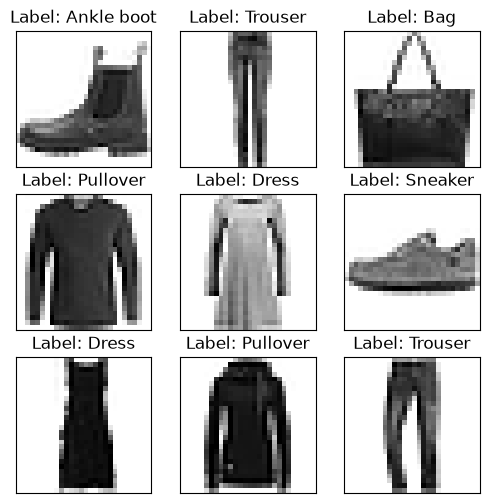

In [3]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
import numpy as np
# Selecting 9 random indices
random_indices = np.random.choice(len(X_train), 9, replace=False)

# Creating a 3x3 grid plot
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f"Label: {class_names[np.argmax(y_train[random_indices[i]])]}")
   

    # Removing axis labels
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()

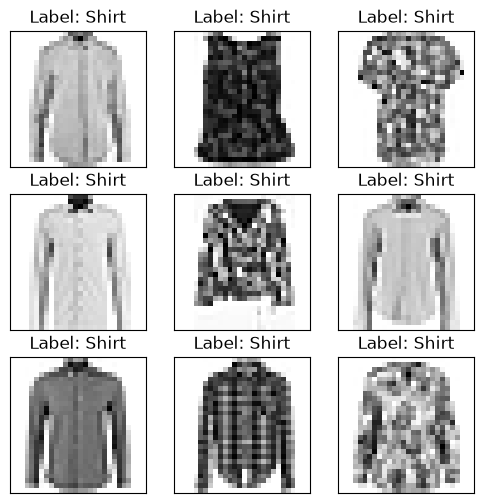

In [4]:
# Selecting 9 random indices of images labelled as "Shirt"
shirt_index = class_names.index("Shirt")  

# Selecting indices of images labelled as "Shirt"
shirt_indices = np.where(np.argmax(y_train, axis=1) == shirt_index)[0]

# Selecting 9 random indices from the Shirt images
random_indices = np.random.choice(shirt_indices, 9, replace=False)
# Creating a 3x3 grid plot
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f"Label: {class_names[np.argmax(y_train[random_indices[i]])]}")

    # Removing axis labels
    ax.set_xticks([])
    ax.set_yticks([])
    
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

The visualized images look as expected, showing different types of clothing items from the Fashion MNIST dataset, such as bags, dresses, T-shirts, shirts, sneakers, sandals, and ankle boots. Each image is displayed in grayscale and has a corresponding class label.

The image quality is relatively low because each image has a resolution of only 28 × 28 pixels. Additionally, the images are in grayscale, meaning that they do not contain color information that could potentially help distinguish between clothing categories.

One noticeable characteristic of the Fashion MNIST dataset is that some clothing categories have very similar visual appearances. For example, the Shirt and T-shirt/top categories can be difficult to distinguish, as some images contain similar shapes and sleeve structures.

These similarities, combined with the low image resolution, may make the classification task more challenging and could lead to misclassification by the CNN model. Therefore, it will be interesting to investigate whether the model can accurately distinguish between these visually similar clothing categories.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [5]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Flatten(input_shape=(28, 28)))

# Output layer
model.add(Dense(10))  # 10 neurons

model.summary()


# Compile the model using `model.compile()`
import tensorflow as tf
model.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    optimizer='adam', # Optimizer
    metrics=['accuracy'] # Metrics to evaluate the model
)

# Train the model with `model.fit()`
model.fit(
    X_train, 
    y_train, 
    epochs=5, 
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)

# Evaluate the model with `model.evaluate()`
loss, accuracy = model.evaluate(X_test, y_test)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step - accuracy: 0.7899 - loss: 0.6290 - val_accuracy: 0.8302 - val_loss: 0.5009
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 941us/step - accuracy: 0.8387 - loss: 0.4737 - val_accuracy: 0.8447 - val_loss: 0.4533
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 927us/step - accuracy: 0.8481 - loss: 0.4439 - val_accuracy: 0.8397 - val_loss: 0.4545
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 909us/step - accuracy: 0.8532 - loss: 0.4286 - val_accuracy: 0.8451 - val_loss: 0.4370
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 913us/step - accuracy: 0.8570 - loss: 0.4177 - val_accuracy: 0.8547 - val_loss: 0.4247
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 876us/step - accuracy: 0.8434 - loss: 0.4529
Loss:     0.45
Accuracy: 84.34%


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

The baseline model achieved a test accuracy of 84.34% and a test loss of approximately 0.45, which I consider a good result. I did not expect the model to perform this well because we used a simple linear model without any activation function in the output layer. The training accuracy increased from 78.99% to 85.70% over the five epochs, while the training loss decreased from 0.6290 to 0.4177, indicating that the model progressively improved its predictions. The validation accuracy and loss also remained relatively stable, suggesting that the model was able to generalize reasonably well to unseen data.

However, the model's simple linear structure limits its ability to learn more complex patterns in the images. Additionally accuracy alone is not sufficient to fully evaluate a model's performance, as it does not provide information about which classes are more difficult to distinguish. Therefore, additional evaluation metrics should also be considered to gain a more complete understanding of the model's performance. Overall, the results are encouraging, especially considering that this is a simple linear baseline model.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [6]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()

# Convolutional layer
model.add(Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)))

# Flatten layer
model.add(Flatten())

# Fully connected hidden layer
model.add(Dense(64, activation='relu'))

# Output layer
model.add(Dense(10, activation='softmax'))

# Display model summary
model.summary()

# Compile the model using `model.compile()`
import tensorflow as tf
model.compile(
    loss='categorical_crossentropy', # Loss function,
    optimizer='adam', # Optimizer
    metrics=['accuracy'] # Metrics to evaluate the model
)

# Train the model
model.fit(
    X_train, 
    y_train, 
    epochs=5, 
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       692,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,098 (2.64 MB)

 Trainable params: 693,098 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8374 - loss: 0.4614 - val_accuracy: 0.8708 - val_loss: 0.3596
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8904 - loss: 0.3041 - val_accuracy: 0.8895 - val_loss: 0.3026
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9082 - loss: 0.2537 - val_accuracy: 0.8969 - val_loss: 0.2858
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9218 - loss: 0.2170 - val_accuracy: 0.8997 - val_loss: 0.2864
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9312 - loss: 0.1885 - val_accuracy: 0.9031 - val_loss: 0.2803
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8942 - loss: 0.3017
Loss:     0.30
Accuracy: 89.42%


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

The CNN model performed better than the baseline model. It achieved an accuracy of 89.42%, compared to 84.34% for the baseline, which is an improvement of 5.08 percentage points. The CNN also had a lower loss of 0.30 compared to 0.45 for the baseline.

I think the main reason for this improvement is the convolutional layer. Unlike the baseline model, which flattens the images before processing them, the CNN can learn features and patterns directly from the images, such as edges, shapes and other visual details. The Flatten layer then converts these features so they can be passed to the Dense layers for classification.

Overall, I think the CNN is better suited for this task because it can recognize patterns in images more effectively. It did take longer to train than the baseline model, but it also achieved better results when tested on unseen data.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [7]:
# A. Test Hyperparameters

# Store the results
hyperparameter_results = []

# Test different numbers of filters
for filters in [16, 32, 64, 128]:

    # Create a new CNN model
    model = Sequential()

    # Convolutional layer
    model.add(Conv2D(filters, (3, 3), activation='relu',
                     input_shape=(28, 28, 1)))

    # Flatten layer
    model.add(Flatten())

    # Fully connected hidden layer
    model.add(Dense(64, activation='relu'))

    # Output layer
    model.add(Dense(10, activation='softmax'))

    # Compile the model
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam', # Optimizer,
        metrics=['accuracy']
    )

    # Train the model
    model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.2
    )

    # Evaluate the model
    loss, accuracy = model.evaluate(X_test, y_test)

    # Save the results
    hyperparameter_results.append({
        'filters': filters,
        'loss': loss,
        'accuracy': accuracy
    })

    print(f"Filters: {filters}, Loss: {loss:.2f}, "
          f"Accuracy: {accuracy*100:.2f}%")


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8488 - loss: 0.4247 - val_accuracy: 0.8782 - val_loss: 0.3423
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8953 - loss: 0.2871 - val_accuracy: 0.8898 - val_loss: 0.3066
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9155 - loss: 0.2321 - val_accuracy: 0.8987 - val_loss: 0.2878
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9280 - loss: 0.1941 - val_accuracy: 0.9001 - val_loss: 0.2816
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9409 - loss: 0.1620 - val_accuracy: 0.8958 - val_loss: 0.2995
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8951 - loss: 0.3132
Filters: 16, Loss: 0.31, Accuracy: 89.51%
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.8537 - loss: 0.4104 - val_accuracy: 0.8788 - val_loss: 0.3341
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9029 - loss: 0.2671 - val_accuracy

In [8]:
import pandas as pd

results_df = pd.DataFrame(hyperparameter_results)

results_df['accuracy'] = results_df['accuracy'] * 100

results_df

,filters,loss,accuracy
0,16,0.313166,89.510000
1,32,0.302181,89.850003
2,64,0.316002,89.649999
3,128,0.330241,90.039998


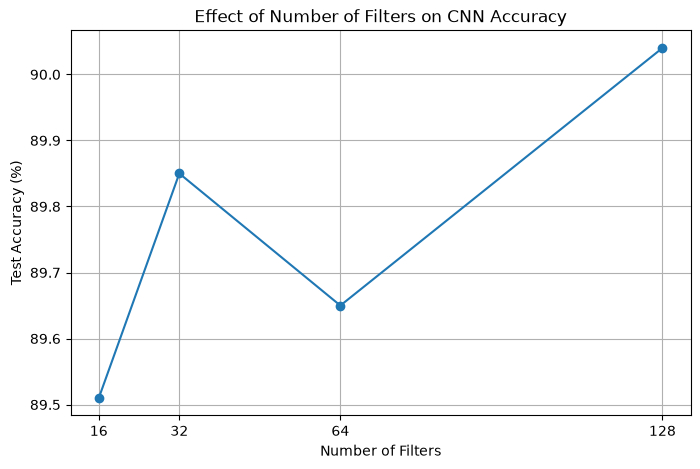

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(
    results_df['filters'],
    results_df['accuracy'],
    marker='o'
)

plt.xlabel('Number of Filters')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Number of Filters on CNN Accuracy')
plt.xticks([16, 32, 64, 128])
plt.grid(True)
plt.show()

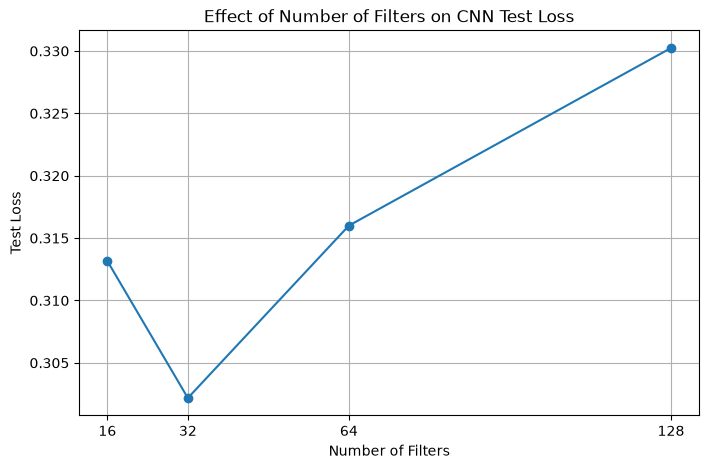

In [12]:
# Plot test loss
plt.figure(figsize=(8, 5))

plt.plot(
    results_df['filters'],
    results_df['loss'],
    marker='o'
)

plt.xlabel('Number of Filters')
plt.ylabel('Test Loss')
plt.title('Effect of Number of Filters on CNN Test Loss')
plt.xticks([16, 32, 64, 128])
plt.grid(True)
plt.show()

In [13]:
# B. Test presence or absence of regularization
from keras.layers import Dropout

# Store the results
regularization_results = []

# Test the model with and without Dropout
for use_dropout in [False, True]:

    # Create a new CNN model
    model = Sequential()

    # Convolutional layer
    model.add(Conv2D(16, (3, 3), activation='relu',
                     input_shape=(28, 28, 1)))

    # Flatten layer
    model.add(Flatten())

    # Fully connected hidden layer
    model.add(Dense(64, activation='relu'))

    # Add Dropout if enabled
    if use_dropout:
        model.add(Dropout(0.3))

    # Output layer
    model.add(Dense(10, activation='softmax'))

    # Compile the model
    model.compile(
        loss='categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    # Train the model
    model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.2
    )

    # Evaluate the model
    loss, accuracy = model.evaluate(X_test, y_test)

    # Store the results
    regularization_results.append({
        'dropout': use_dropout,
        'loss': loss,
        'accuracy': accuracy
    })

    print(f"Dropout: {use_dropout}, Loss: {loss:.2f}, "
          f"Accuracy: {accuracy*100:.2f}%")

Epoch 1/5


d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8570 - loss: 0.4081 - val_accuracy: 0.8850 - val_loss: 0.3247
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9005 - loss: 0.2732 - val_accuracy: 0.9003 - val_loss: 0.2822
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9191 - loss: 0.2217 - val_accuracy: 0.9082 - val_loss: 0.2673
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9315 - loss: 0.1844 - val_accuracy: 0.8997 - val_loss: 0.2822
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9425 - loss: 0.1560 - val_accuracy: 0.9038 - val_loss: 0.2825
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8994 - loss: 0.3083
Dropout: False, Loss: 0.31, Accuracy: 89.94%
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.8198 - loss: 0.5142 - val_accuracy: 0.8755 - val_loss: 0.3402
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.8723 - loss: 0.3547 - val_accuracy: 0.8913 

In [14]:

regularization_df = pd.DataFrame(regularization_results)

# Convert accuracy to percentage
regularization_df['accuracy'] = regularization_df['accuracy'] * 100

# Rename the values for easier reading
regularization_df['dropout'] = regularization_df['dropout'].map({
    False: 'Without Dropout',
    True: 'With Dropout'
})

regularization_df

,dropout,loss,accuracy
0,Without Dropout,0.308294,89.940000
1,With Dropout,0.303079,89.020002


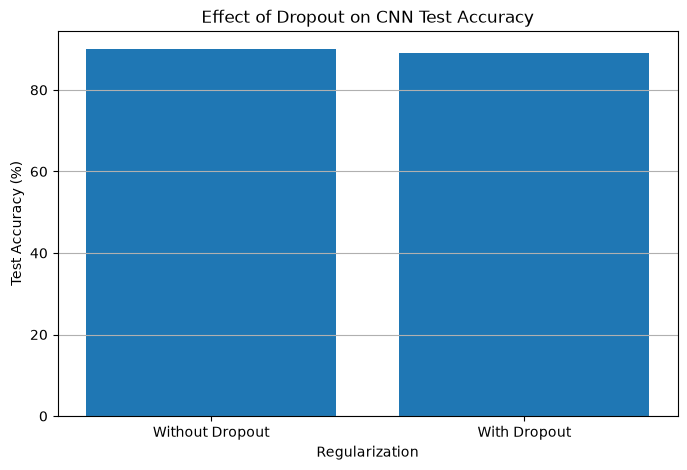

In [16]:
plt.figure(figsize=(8, 5))

plt.bar(
    regularization_df['dropout'],
    regularization_df['accuracy']
)

plt.xlabel('Regularization')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Dropout on CNN Test Accuracy')
plt.grid(axis='y')
plt.show()

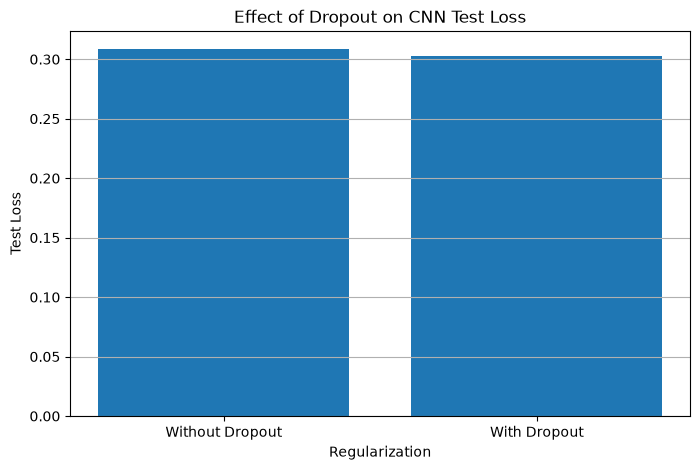

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    regularization_df['dropout'],
    regularization_df['loss']
)

plt.xlabel('Regularization')
plt.ylabel('Test Loss')
plt.title('Effect of Dropout on CNN Test Loss')
plt.grid(axis='y')
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

I tested different numbers of filters (16, 32, 64 and 128) to see how they affected the CNN's performance. The best result in terms of accuracy was achieved with 128 filters, with an accuracy of 90.04% and a loss of 0.33. However, 32 filters achieved a slightly lower accuracy of 89.85% but a lower loss of 0.30. This suggests that increasing the number of filters does not necessarily improve both accuracy and loss, and that using more filters does not always lead to better overall performance.

I also tested Dropout as a regularization technique by comparing the model with and without it. In this case, adding Dropout did not improve the accuracy. The model without Dropout achieved 89.94% accuracy, compared to 89.02% with Dropout. However, the model with Dropout had a slightly lower loss (0.30 compared to 0.31). This shows that Dropout did not improve the overall performance in terms of accuracy, although it slightly reduced the loss.

Overall, the best result in terms of accuracy was achieved with 128 filters and without Dropout, reaching an accuracy of 90.04%. However, 32 filters provided a better balance between accuracy and loss, with 89.85% accuracy and a loss of 0.30. I think increasing the number of filters provided the model with more capacity to learn useful features from the images, although the improvements were relatively small. Dropout may also have been unnecessary for this model, as it reduced the accuracy rather than improving it.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [18]:
# Create a simple CNN model
model = Sequential()

# Convolutional layer
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))

# Flatten layer
model.add(Flatten())

# Fully connected hidden layer
model.add(Dense(64, activation='relu'))

# Output layer
model.add(Dense(10, activation='softmax'))

# Display model summary
model.summary()

# Compile the model using `model.compile()`
import tensorflow as tf
model.compile(
    loss='categorical_crossentropy', # Loss function,
    optimizer='adam', # Optimizer
    metrics=['accuracy'] # Metrics to evaluate the model
)

# Train the model
model.fit(
    X_train, 
    y_train, 
    epochs=5, 
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

d:\Sara'sWork\DSI_MachineLearningCourse\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │     1,384,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,385,482 (5.29 MB)

 Trainable params: 1,385,482 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.8535 - loss: 0.4169 - val_accuracy: 0.8858 - val_loss: 0.3181
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.8987 - loss: 0.2771 - val_accuracy: 0.8952 - val_loss: 0.2979
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9153 - loss: 0.2291 - val_accuracy: 0.8966 - val_loss: 0.2887
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9291 - loss: 0.1902 - val_accuracy: 0.9016 - val_loss: 0.2860
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.9411 - loss: 0.1600 - val_accuracy: 0.9001 - val_loss: 0.3007
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8905 - loss: 0.3186
Loss:     0.32
Accuracy: 89.05%


Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?**

The final model achieved an accuracy of 89.05% and a loss of 0.32. This was a considerable improvement over the baseline model, which achieved an accuracy of 84.34% and a loss of 0.45. This indicates that using convolutional layers allowed the model to learn more useful features from the images and improve its ability to classify them. However, the final model's performance was slightly lower than that of the original CNN model, which achieved an accuracy of 89.42% and a loss of 0.30. The difference is relatively small, suggesting that both CNN models performed similarly overall.

In the previous experiments, I tested different numbers of filters (16, 32, 64, and 128) to investigate their effect on model performance. The results showed that 128 filters achieved the highest accuracy of 90.04%, while 32 filters achieved the lowest loss of 0.30. This suggests that increasing the number of filters does not necessarily improve both accuracy and loss. I also compared the model with and without Dropout. Adding Dropout reduced the accuracy from 89.94% to 89.02%, although it resulted in a slightly lower loss. Based on these results, I chose 32 filters without Dropout for the final model, as this configuration offered a good balance between accuracy, loss, and model complexity.

The final model's accuracy was slightly lower than the results obtained in some of the previous experiments. This could be due to differences between number of filters, individual training runs, as model performance can vary depending on factors such as random initialization and the training process. Overall, the results demonstrate that the CNN models performed considerably better than the simple linear baseline.

If I had more time, I would experiment with different combinations of filters and Dropout rates to see whether they could improve performance when used together. I would also test different learning rates, batch sizes, and numbers of training epochs. Another possible experiment would be to add more convolutional layers or use data augmentation to help the model learn more diverse image features and improve its ability to generalize to unseen data. Finally, I would examine other evaluation metrics, such as precision, recall, and F1-score, to better understand which classes the model has difficulty distinguishing.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.